# 🌬️ WindWatch AI – Wind Turbine Status Prediction

**Capstone project · Machine Learning · End-to-end (data → model → web app → AWS)**

### Problem statement
Wind turbines send a reading from dozens of sensors every 10 minutes (SCADA data). Operators need to know *what state the turbine is in* (running normally, in service, or in another downtime state) without manually checking every sensor. This notebook builds a model that **predicts the turbine's operating status (`status_type_id`) from its sensor readings**.

### Why it matters
Catching abnormal states early reduces downtime, supports maintenance planning and protects energy output.

### Workflow
`Imports → Data Load → Data Cleaning → Data Transformation → EDA → Model Development → Best Model & Why → Save Model (joblib) for deployment`

### Quick glossary
| Term | Meaning |
|---|---|
| **SCADA** | The monitoring system that logs turbine sensors every 10 minutes |
| **Target** | The column we predict: `status_type_id` (0, 3 or 5) |
| **Macro-F1** | Score that treats every class equally – the right yardstick when classes are imbalanced |
| **Pipeline** | Imputer + scaler + model packaged together so training and prediction use identical steps |
| **joblib** | File format used to save the trained pipeline so the web app can load it |

> Put `windwatchaidataset.xlsx` in this folder or in `../data/` (or change `FILE_PATH` below).

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

## 2. Data Load

In [2]:
import os
candidates = ["windwatchaidataset.xlsx", "../data/windwatchaidataset.xlsx"]
FILE_PATH = next((p for p in candidates if os.path.exists(p)), candidates[0])   # change if the file is elsewhere
print("Reading:", FILE_PATH)

df_raw = pd.read_excel(FILE_PATH)       # ~160k rows, takes about a minute
print("Raw shape:", df_raw.shape)
df_raw.head()

Reading: ../data/windwatchaidataset.xlsx


Raw shape: (160640, 86)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_1_avg,sensor_2_avg,wind_speed_3_avg,wind_speed_4_avg,...,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,sensor_52_avg,sensor_52_max,sensor_52_min,sensor_52_std,sensor_53_avg
0,2019-04-04 02:30:00,11,0,train,5,15,257,-1.8,2.7,2.7,...,-375,0,0,-885,-375,2,2.2,1.6,0.1,17
1,2019-04-04 02:40:00,11,1,train,5,15,267.3,13.4,2.6,2.6,...,-226,0,0,-822,-226,1.9,2.2,1.5,0.2,17
2,2019-04-04 02:50:00,11,2,train,5,15,280.9,27,3,3,...,-360,0,0,-884,-360,2.2,2.6,1.7,0.2,17
3,2019-04-04 03:00:00,11,3,train,5,15,256.5,6.8,2.8,2.8,...,-356,0,0,-869,-356,2.2,2.6,1.8,0.2,17
4,2019-04-04 03:10:00,11,4,train,5,15,260.2,7.4,3.4,3.4,...,-13,771,0,20,759,4.5,12.2,2.1,3.5,17


In [3]:
# Quick look at column types – many numeric columns were read as 'object' (a sign of dirty rows)
print(df_raw.dtypes.value_counts())
print("\nColumn groups:")
print("  identifiers :", ["time_stamp", "asset_id", "id", "train_test"])
print("  target      : status_type_id")
print("  sensors     :", df_raw.shape[1] - 5)

object    85
str        1
Name: count, dtype: int64

Column groups:
  identifiers : ['time_stamp', 'asset_id', 'id', 'train_test']
  target      : status_type_id
  sensors     : 81


## 3. Data Cleaning

Problems found in the raw file and how they are handled:

| Problem | Fix |
|---|---|
| Completely empty rows | drop them |
| A header row repeated in the middle of the data (where two turbine files were joined) | drop it |
| Numeric columns stored as text because of that header row | convert with `pd.to_numeric` |
| `time_stamp` stored as text | convert to `datetime` |
| Constant columns (no information) | drop them |
| A few missing sensor values | imputed later, inside the model pipeline (no data leakage) |

In [4]:
df = df_raw.copy()

# 1) empty rows
n_empty = df.isna().all(axis=1).sum()
df = df.dropna(how="all")

# 2) repeated header row(s)
mask_header = df["time_stamp"].astype(str) == "time_stamp"
n_header = mask_header.sum()
df = df[~mask_header]
print(f"Dropped {n_empty} empty rows and {n_header} repeated header row(s)")

# 3) correct data types
df["time_stamp"] = pd.to_datetime(df["time_stamp"])
df["asset_id"] = df["asset_id"].astype(int)
df["status_type_id"] = df["status_type_id"].astype(int)
sensor_cols = [c for c in df.columns if c not in ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]]
df[sensor_cols] = df[sensor_cols].apply(pd.to_numeric, errors="coerce")

# 4) duplicates
n_dup = df.duplicated(subset=["asset_id", "time_stamp"]).sum()
df = df.drop_duplicates(subset=["asset_id", "time_stamp"])
print("Duplicate asset/timestamp rows removed:", n_dup)

# 5) constant columns
const_cols = [c for c in sensor_cols if df[c].nunique(dropna=True) <= 1]
df = df.drop(columns=const_cols)
sensor_cols = [c for c in sensor_cols if c not in const_cols]
print("Constant columns dropped:", const_cols)

df = df.sort_values(["asset_id", "time_stamp"]).reset_index(drop=True)
print("\nClean shape:", df.shape)

Dropped 2 empty rows and 1 repeated header row(s)


Duplicate asset/timestamp rows removed: 0
Constant columns dropped: ['sensor_46', 'sensor_49']

Clean shape: (160637, 84)


In [5]:
# Missing values after cleaning
missing = df.isna().sum()
print("Columns with missing values:\n", missing[missing > 0])
print("\nTrain/Prediction split provided in the data:\n", df["train_test"].value_counts())
print("\nTarget distribution:\n", df["status_type_id"].value_counts())

Columns with missing values:
 sensor_14_avg    1
sensor_22_avg    1
dtype: int64

Train/Prediction split provided in the data:
 train_test
train         154132
prediction      6505
Name: count, dtype: int64

Target distribution:
 status_type_id
0    126529
5     30746
3      3362
Name: count, dtype: int64


## 4. Data Transformation

* Create time features (`hour`, `month`) from `time_stamp`
* Encode the target (`0, 3, 5` → `0, 1, 2`)
* Use the dataset's own `train_test` column for the split (`train` = fit, `prediction` = hold-out test set, which also has labels)
* Remove highly correlated features (|r| > 0.98), found on the **training data only**
* Imputation and scaling happen inside the model pipelines so the test data never leaks into training

In [6]:
# time features
df["hour"] = df["time_stamp"].dt.hour
df["month"] = df["time_stamp"].dt.month

# target encoding
status_map = {0: 0, 3: 1, 5: 2}
inv_status = {v: k for k, v in status_map.items()}
df["target"] = df["status_type_id"].map(status_map)
class_names = [f"status {inv_status[i]}" for i in range(3)]

feature_cols = sensor_cols + ["asset_id", "hour", "month"]

train_df = df[df["train_test"] == "train"]
test_df  = df[df["train_test"] == "prediction"]

# drop near-duplicate (highly correlated) features, decided on train only
corr = train_df[feature_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if (upper[c] > 0.98).any()]
feature_cols = [c for c in feature_cols if c not in drop_corr]
print(f"Dropped {len(drop_corr)} highly-correlated features; {len(feature_cols)} features remain")

X_train, y_train = train_df[feature_cols], train_df["target"]
X_test,  y_test  = test_df[feature_cols],  test_df["target"]
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nTrain class share:\n", y_train.value_counts(normalize=True).round(3).rename(index=lambda i: class_names[i]))

Dropped 21 highly-correlated features; 61 features remain
X_train: (154132, 61) | X_test: (6505, 61)

Train class share:
 target
status 0    0.784
status 5    0.195
status 3    0.021
Name: proportion, dtype: float64


## 5. Exploratory Data Analysis (EDA)

Key signal columns (names are anonymised in the dataset): `wind_speed_3_avg` = wind speed, `power_29_avg` = power output, `sensor_0_avg` / `sensor_18_avg` = other operating sensors.

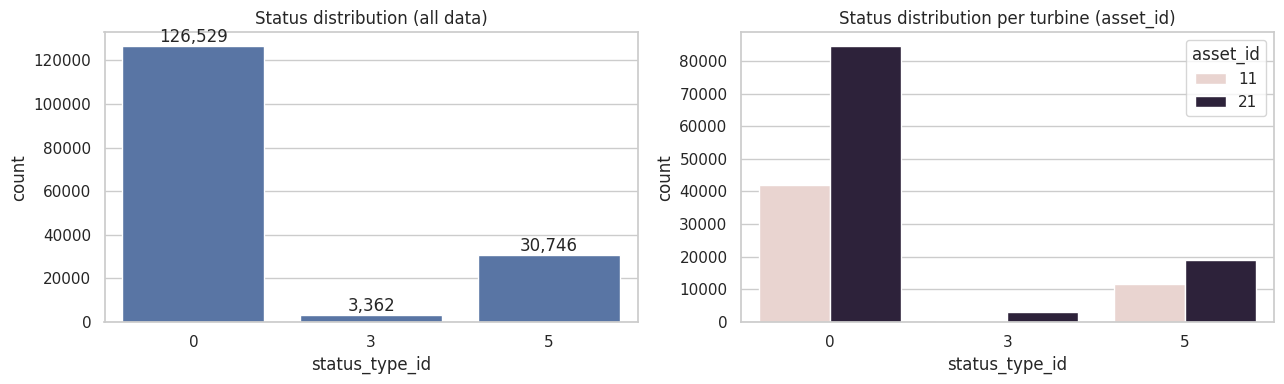

In [7]:
# Graph 1 – Target distribution, overall and per turbine
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = [0, 3, 5]
sns.countplot(data=df, x="status_type_id", order=order, ax=ax[0])
ax[0].set_title("Status distribution (all data)")
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
sns.countplot(data=df, x="status_type_id", hue="asset_id", order=order, ax=ax[1])
ax[1].set_title("Status distribution per turbine (asset_id)")
plt.tight_layout(); plt.show()

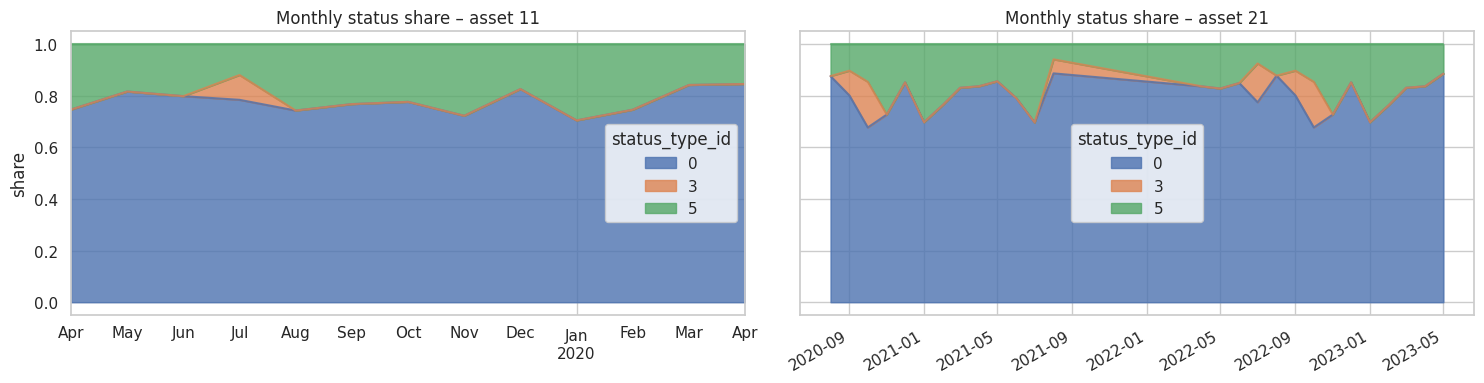

In [8]:
# Graph 2 – Status over time (monthly share) for each turbine
df["ym"] = df["time_stamp"].dt.to_period("M").dt.to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, (aid, g) in zip(axes, df.groupby("asset_id")):
    share = pd.crosstab(g["ym"], g["status_type_id"], normalize="index")
    share.plot.area(ax=ax, alpha=0.8)
    ax.set_title(f"Monthly status share – asset {aid}"); ax.set_xlabel(""); ax.set_ylabel("share")
plt.tight_layout(); plt.show()

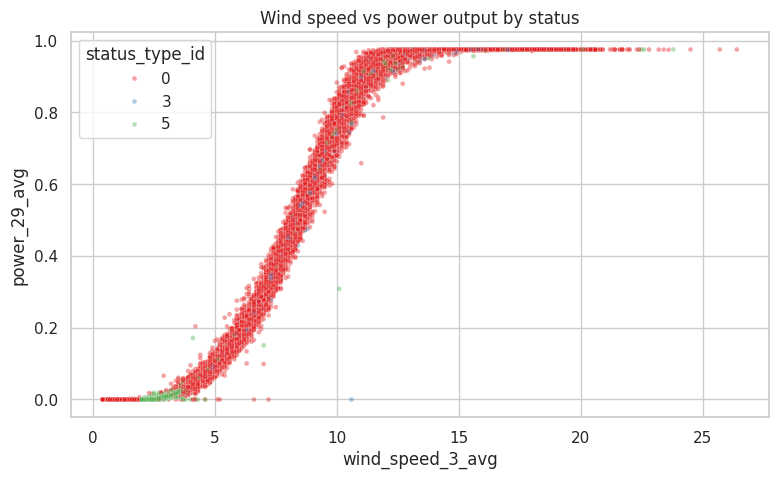

In [9]:
# Graph 3 – Power curve: wind speed vs power, coloured by status
s = df.sample(25000, random_state=RANDOM_STATE)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=s, x="wind_speed_3_avg", y="power_29_avg", hue="status_type_id",
                palette="Set1", alpha=0.4, s=12)
plt.title("Wind speed vs power output by status"); plt.show()

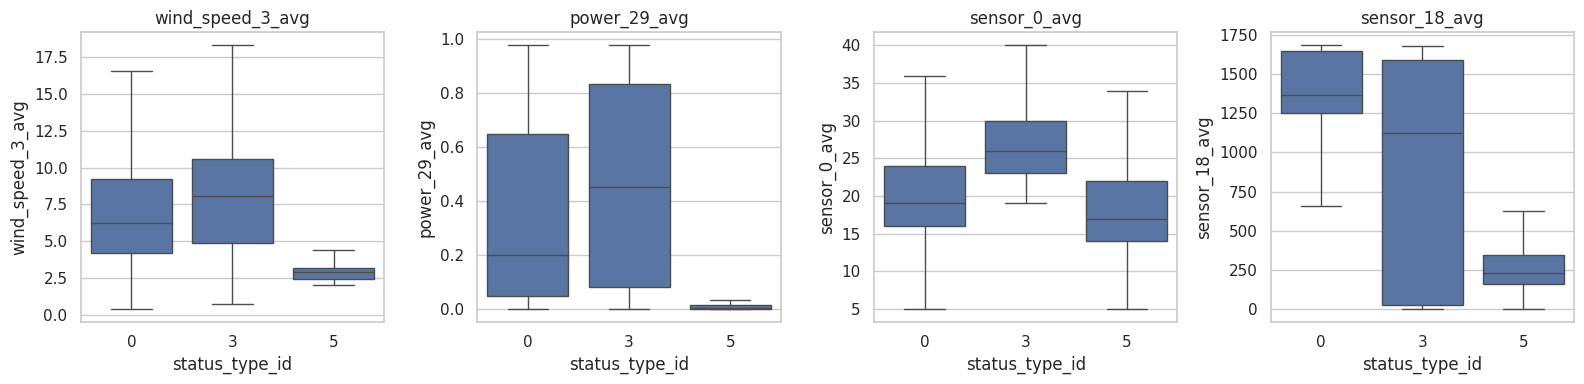

In [10]:
# Graph 4 – Boxplots of key sensors by status
key = ["wind_speed_3_avg", "power_29_avg", "sensor_0_avg", "sensor_18_avg"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, key):
    sns.boxplot(data=df, x="status_type_id", y=c, order=order, ax=ax, showfliers=False)
    ax.set_title(c)
plt.tight_layout(); plt.show()

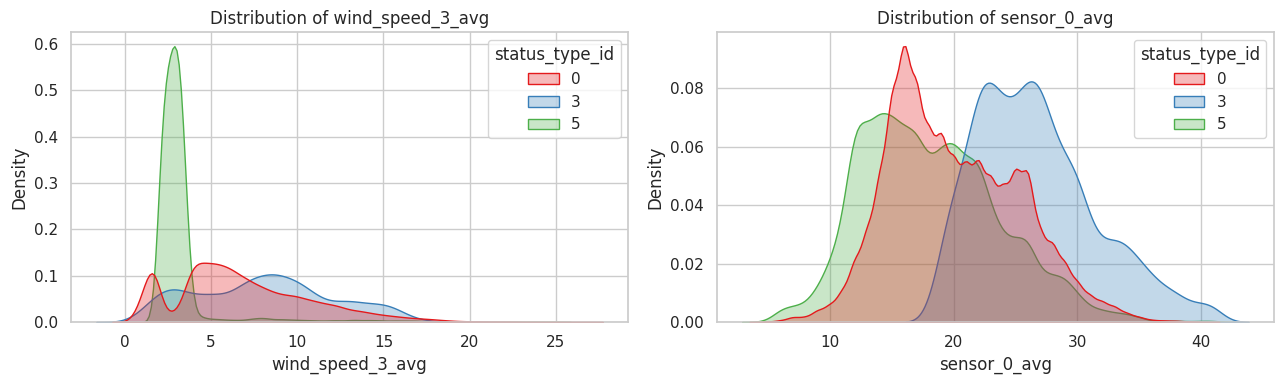

In [11]:
# Graph 5 – Distribution (KDE) of wind speed and sensor_0 by status
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["wind_speed_3_avg", "sensor_0_avg"]):
    sns.kdeplot(data=df, x=c, hue="status_type_id", common_norm=False, fill=True, alpha=0.3, ax=ax, palette="Set1")
    ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.show()

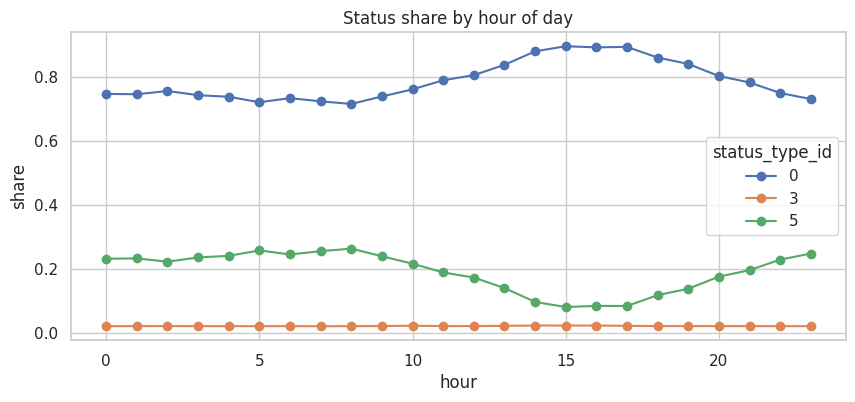

In [12]:
# Graph 6 – Status share by hour of day
hour_share = pd.crosstab(df["hour"], df["status_type_id"], normalize="index")
hour_share.plot(figsize=(10, 4), marker="o")
plt.title("Status share by hour of day"); plt.ylabel("share"); plt.show()

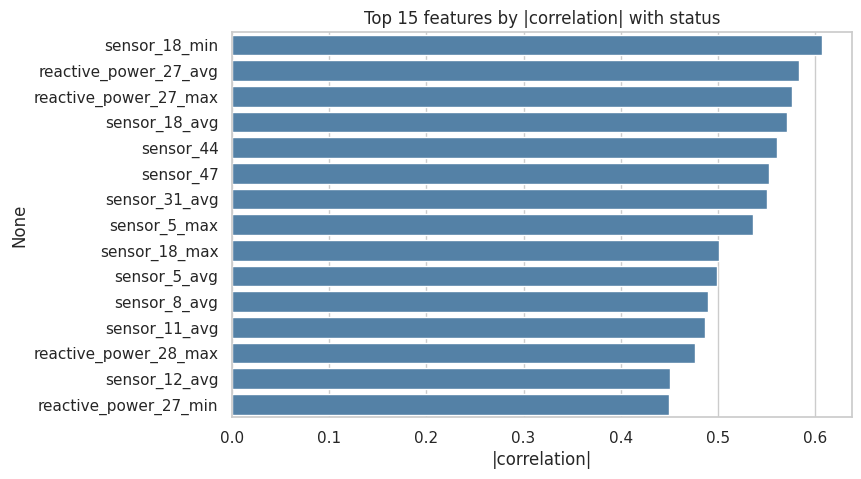

In [13]:
# Graph 7 – Features most correlated with the target
corr_target = train_df[feature_cols].corrwith(train_df["target"]).abs().sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=corr_target.values, y=corr_target.index, color="steelblue")
plt.title("Top 15 features by |correlation| with status"); plt.xlabel("|correlation|"); plt.show()

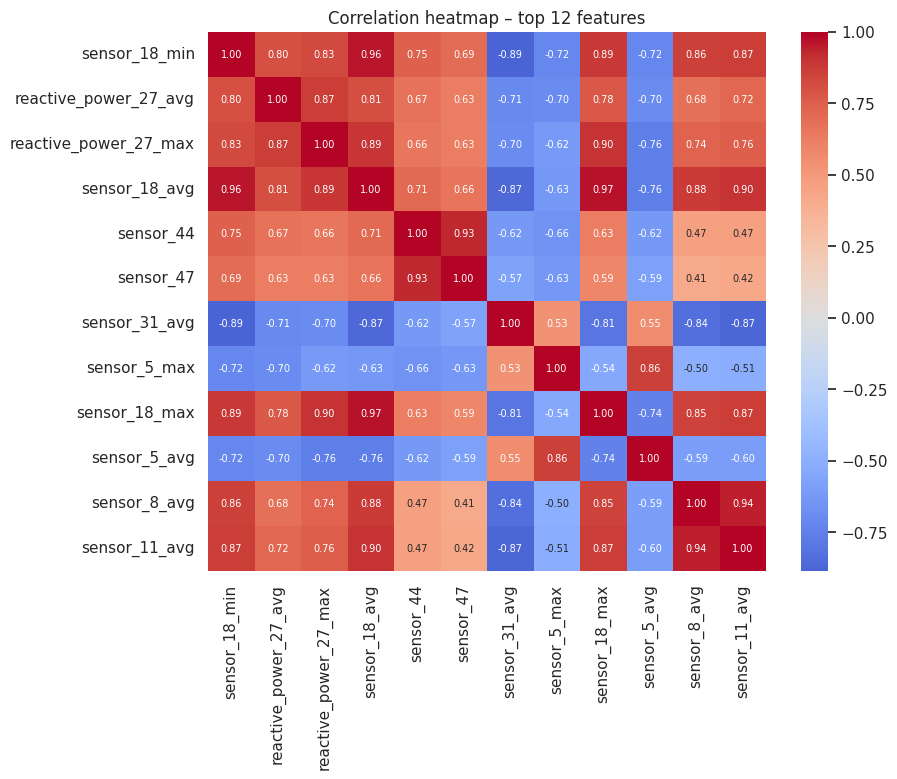

In [14]:
# Graph 8 – Correlation heatmap of the top features
top = corr_target.index[:12].tolist()
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap – top 12 features"); plt.show()

## 6. Model Development

Because the classes are imbalanced (status 0 is by far the largest), every model uses **class weighting**, and we compare models mainly on **macro F1** (treats all classes equally) rather than accuracy alone.

Four models, from simple to powerful:
1. **Logistic Regression** – linear baseline
2. **Decision Tree** – simple, interpretable
3. **Random Forest** – many trees averaged (bagging)
4. **Histogram Gradient Boosting** – trees built one after another, each fixing the previous errors (boosting)

In [15]:
models = {
    "Logistic Regression": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=300, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=RANDOM_STATE))]),
    "Hist Gradient Boosting": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight="balanced",
                                               random_state=RANDOM_STATE))]),
}

results, fitted = [], {}
for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0
    pred_tr, pred_te = pipe.predict(X_train), pipe.predict(X_test)
    results.append({
        "Model": name,
        "Train macro-F1": f1_score(y_train, pred_tr, average="macro"),
        "Test accuracy": accuracy_score(y_test, pred_te),
        "Test precision (macro)": precision_score(y_test, pred_te, average="macro"),
        "Test recall (macro)": recall_score(y_test, pred_te, average="macro"),
        "Test macro-F1": f1_score(y_test, pred_te, average="macro"),
        "Test weighted-F1": f1_score(y_test, pred_te, average="weighted"),
        "Fit time (s)": fit_time,
    })
    fitted[name] = pipe
    print(f"✔ {name} trained in {fit_time:.1f}s")

results_df = pd.DataFrame(results).set_index("Model").sort_values("Test macro-F1", ascending=False)
results_df.round(3)

✔ Logistic Regression trained in 13.6s


✔ Decision Tree trained in 5.4s


✔ Random Forest trained in 66.8s


✔ Hist Gradient Boosting trained in 8.9s


,Train macro-F1,Test accuracy,Test precision (macro),Test recall (macro),Test macro-F1,Test weighted-F1,Fit time (s)
Model,,,,,,,
Logistic Regression,0.635,0.862,0.607,0.818,0.654,0.889,13.580
Decision Tree,0.824,0.960,0.668,0.664,0.640,0.950,5.399
Random Forest,0.999,0.963,0.613,0.661,0.635,0.952,66.821
Hist Gradient Boosting,0.951,0.959,0.603,0.659,0.629,0.949,8.914


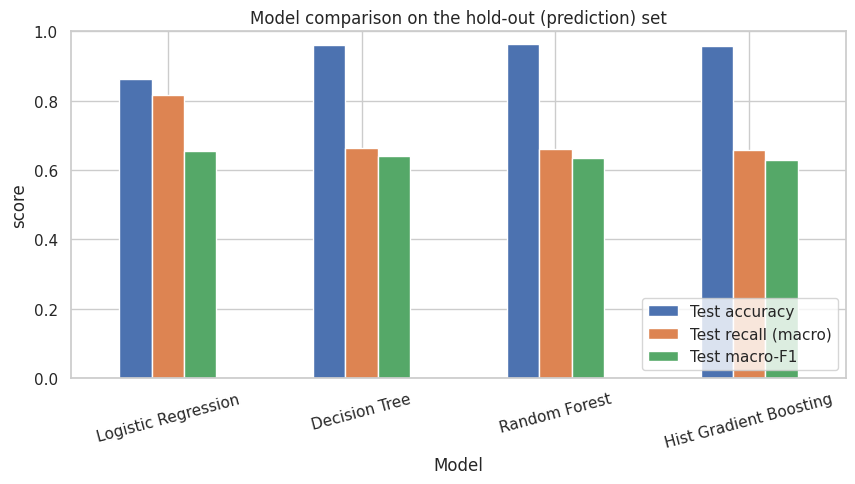

In [16]:
# Compare models visually
metrics = ["Test accuracy", "Test recall (macro)", "Test macro-F1"]
results_df[metrics].plot.bar(figsize=(10, 4.5), rot=15)
plt.title("Model comparison on the hold-out (prediction) set"); plt.ylabel("score"); plt.ylim(0, 1)
plt.legend(loc="lower right"); plt.show()

## 7. Best Model & Why

In [17]:
best_name = results_df.index[0]
best_model = fitted[best_name]
print("🏆 Best model (highest test macro-F1):", best_name)
print()
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

🏆 Best model (highest test macro-F1): Logistic Regression

              precision    recall  f1-score   support

    status 0      0.988     0.852     0.915      5665
    status 3      0.142     0.604     0.230       144
    status 5      0.691     0.997     0.816       696

    accuracy                          0.862      6505
   macro avg      0.607     0.818     0.654      6505
weighted avg      0.938     0.862     0.889      6505



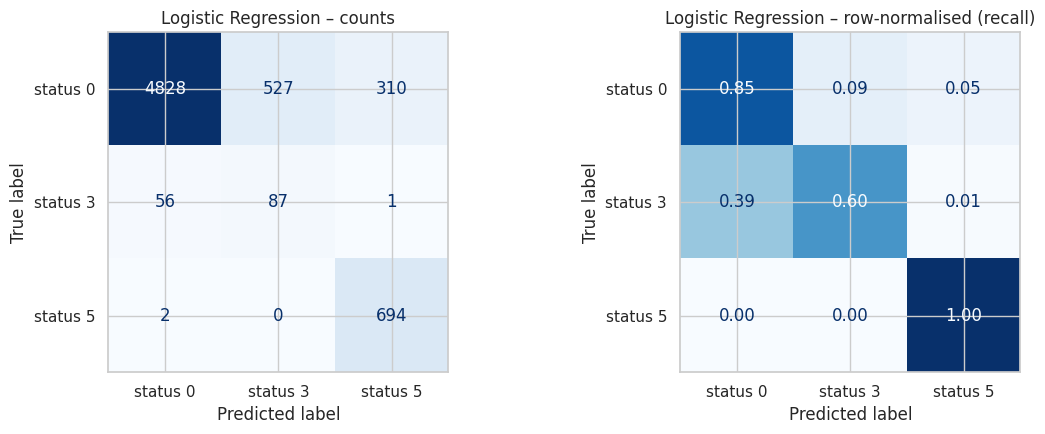

In [18]:
# Confusion matrix of the best model
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"{best_name} – counts")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, ax=ax[1],
                                        cmap="Blues", normalize="true", values_format=".2f", colorbar=False)
ax[1].set_title(f"{best_name} – row-normalised (recall)")
plt.tight_layout(); plt.show()

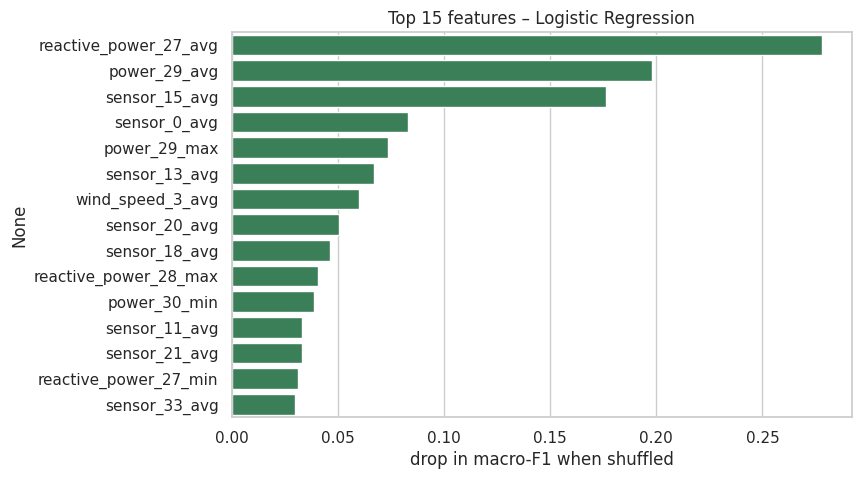

In [19]:
# Which features drive the best model? (permutation importance on a test sample)
samp = X_test.sample(min(4000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(best_model, samp, y_test.loc[samp.index], scoring="f1_macro",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="seagreen")
plt.title(f"Top 15 features – {best_name}"); plt.xlabel("drop in macro-F1 when shuffled"); plt.show()

In [20]:
print("Summary table (sorted by test macro-F1):")
display(results_df.round(3))

Summary table (sorted by test macro-F1):


,Train macro-F1,Test accuracy,Test precision (macro),Test recall (macro),Test macro-F1,Test weighted-F1,Fit time (s)
Model,,,,,,,
Logistic Regression,0.635,0.862,0.607,0.818,0.654,0.889,13.580
Decision Tree,0.824,0.960,0.668,0.664,0.640,0.950,5.399
Random Forest,0.999,0.963,0.613,0.661,0.635,0.952,66.821
Hist Gradient Boosting,0.951,0.959,0.603,0.659,0.629,0.949,8.914


### 🏆 Best model: Logistic Regression (selected by hold-out macro-F1)

| Model | Test accuracy | Macro recall | Test macro-F1 | Train macro-F1 |
|---|---|---|---|---|
| **Logistic Regression** | 0.862 | **0.818** | **0.654** | 0.635 |
| Decision Tree | 0.960 | 0.664 | 0.640 | 0.824 |
| Random Forest | 0.963 | 0.661 | 0.635 | 0.999 |
| Hist Gradient Boosting | 0.959 | 0.659 | 0.629 | 0.951 |

**Why Logistic Regression is the best choice here**

1. **The right metric.** About 78% of rows are status 0, 19.5% are status 5 and only 2% are status 3. A model that mostly says "normal" already scores high accuracy, so accuracy is misleading. Macro-F1 gives every status equal weight, which is why it decides the ranking.
2. **It catches the abnormal states.** Logistic Regression has by far the best macro recall (0.82 vs about 0.66). On the hold-out set it finds 99.7% of status 5 rows and 60% of status 3 rows. In turbine monitoring, missing a non-normal state usually costs more than a false alarm.
3. **It generalises.** Its train macro-F1 (0.635) is about the same as its test macro-F1 (0.654), so there is no overfitting. Random Forest goes from 0.999 on train to 0.635 on test, Gradient Boosting from 0.951 to 0.629 and the Decision Tree from 0.824 to 0.640. The tree models memorise the training period and do not transfer well to the hold-out windows.
4. **It is simple and fast.** It trains in seconds, is easy to explain (coefficients) and is cheap to run on live data.

**Honest caveats**

* The gap between models is small (macro-F1 0.629 – 0.654), so treat this as "slightly best", not a landslide.
* The tree models have much higher plain accuracy (about 96% vs 86%) and weighted-F1 (about 0.95 vs 0.89) because they are better at the dominant "normal" class. If fewer false alarms matter more than catching every fault, Random Forest or the Decision Tree is a reasonable pick instead.
* Status 3 is still hard for every model (Logistic Regression precision is only about 0.14, so many false alarms).

**Ideas to improve further:** rolling-window / lag features (a fault builds up over time), tuning the decision threshold for status 3, time-aware cross-validation, and hyper-parameter tuning of the boosting model.

## 8. Save the Model for Deployment (joblib)

A trained model only lives in memory. To use it in a web app we **serialise** the whole pipeline (imputer + scaler + model) with `joblib` and bundle it with the information the app needs: feature names, default values (training medians), valid ranges, class labels, metrics, feature importance and a few real sample rows.

In [21]:
import joblib

# Meaning of the status codes (standard SCADA coding – confirm against your data dictionary)
STATUS_LABELS = {0: "Normal Operation", 3: "Service / Maintenance", 5: "Other / Downtime"}

importance_all = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

# a few real rows from the hold-out set, so the web app can offer "load sample row" buttons
samples = []
for code_, g in test_df.groupby("status_type_id"):
    for _, row in g.sample(2, random_state=RANDOM_STATE).iterrows():
        samples.append({"actual_status": int(code_), "values": {c: float(row[c]) for c in feature_cols}})

bundle = {
    "pipeline": best_model,                       # imputer + scaler + classifier
    "model_name": best_name,
    "features": feature_cols,
    "defaults": {c: float(v) for c, v in X_train.median().items()},
    "ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in feature_cols},
    "class_codes": [inv_status[i] for i in range(3)],      # model output index -> original status code
    "status_labels": STATUS_LABELS,
    "metrics": results_df.round(4).reset_index().to_dict("records"),
    "feature_importance": {k: float(v) for k, v in importance_all.items()},
    "samples": samples,
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "sklearn_version": __import__("sklearn").__version__,
}
os.makedirs("../model", exist_ok=True)
joblib.dump(bundle, "../model/wind_turbine_model.joblib", compress=3)
print("Saved ../model/wind_turbine_model.joblib  (", round(os.path.getsize("../model/wind_turbine_model.joblib")/1024), "KB )")

# a small demo file the web app can upload (raw column names, includes the real status for comparison)
os.makedirs("../sample_data", exist_ok=True)
parts = [test_df[test_df.status_type_id == 0].sample(120, random_state=1),
         test_df[test_df.status_type_id == 3].sample(60, random_state=1),
         test_df[test_df.status_type_id == 5].sample(120, random_state=1)]
demo = pd.concat(parts).sort_values(["asset_id", "time_stamp"])
demo[["time_stamp", "asset_id", "status_type_id"] + sensor_cols].to_csv("../sample_data/sample_upload.csv", index=False)
print("Saved ../sample_data/sample_upload.csv", demo.shape[0], "rows")

Saved ../model/wind_turbine_model.joblib  ( 9 KB )


Saved ../sample_data/sample_upload.csv 300 rows


## 9. Test the Saved Model (what the web app does)

In [22]:
loaded = joblib.load("../model/wind_turbine_model.joblib")
row = pd.DataFrame([loaded["samples"][0]["values"]])[loaded["features"]]
proba = loaded["pipeline"].predict_proba(row)[0]
pred_idx = int(np.argmax(proba))
print("Actual status   :", loaded["samples"][0]["actual_status"])
print("Predicted status:", loaded["class_codes"][pred_idx], "-", loaded["status_labels"][loaded["class_codes"][pred_idx]])
print("Probabilities   :", {loaded["class_codes"][i]: round(float(p), 3) for i, p in enumerate(proba)})

Actual status   : 0
Predicted status: 0 - Normal Operation
Probabilities   : {0: 0.998, 3: 0.001, 5: 0.001}


## 10. Deployment overview

```
Browser (HTML/CSS/JS)  ──►  Flask API (application.py)  ──►  joblib pipeline  ──►  prediction + probabilities
        ▲                         │ gunicorn
        └──── JSON / CSV ◄────────┘      hosted on AWS (Elastic Beanstalk / EC2 / App Runner)
```
See the project `README.md` and `docs/DEPLOYMENT_AWS.md` for the full steps.